In [15]:
# Cell 1: Imports and Load Data
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, r2_score

from lightgbm import LGBMRegressor

import matplotlib.pyplot as plt
import seaborn as sns

# Load data
airbnb_df = pd.read_csv('airbnd.csv', encoding='utf-8')  # change filename if needed
print("Data loaded, shape:", airbnb_df.shape)
print(airbnb_df.head())


Data loaded, shape: (102599, 26)
        id                                              NAME      host id  \
0  1001254                Clean & quiet apt home by the park  80014485718   
1  1002102                             Skylit Midtown Castle  52335172823   
2  1002403               THE VILLAGE OF HARLEM....NEW YORK !  78829239556   
3  1002755                                               NaN  85098326012   
4  1003689  Entire Apt: Spacious Studio/Loft by central park  92037596077   

  host_identity_verified host name neighbourhood group neighbourhood  \
0            unconfirmed  Madaline            Brooklyn    Kensington   
1               verified     Jenna           Manhattan       Midtown   
2                    NaN     Elise           Manhattan        Harlem   
3            unconfirmed     Garry            Brooklyn  Clinton Hill   
4               verified    Lyndon           Manhattan   East Harlem   

        lat      long        country  ... service fee minimum nights  \

/tmp/ipython-input-632439566.py:18: DtypeWarning: Columns (25) have mixed types. Specify dtype option on import or set low_memory=False.
  airbnb_df = pd.read_csv('airbnd.csv', encoding='utf-8')  # change filename if needed


In [16]:
# Cell 2: Clean numeric columns and engineer features

df = airbnb_df.copy()

# Columns that look numeric but may have symbols
num_like_cols = ['price','service fee','minimum nights','number of reviews',
                'reviews per month','review rate number','calculated host listings count',
                'availability 365','Construction year','lat','long']

for col in num_like_cols:
    if col in df.columns:
        s = df[col].astype(str).str.replace('$','', regex=False).str.replace(',','', regex=False).str.replace(' ','', regex=False)
        df[col] = pd.to_numeric(s, errors='coerce')

# Parse last review date and create recency feature
if 'last review' in df.columns:
    df['last_review_dt'] = pd.to_datetime(df['last review'], errors='coerce', dayfirst=True)
    df['days_since_last_review'] = (pd.Timestamp.today() - df['last_review_dt']).dt.days

print("Data cleaning done.")


Data cleaning done.


In [17]:
# Cell 3: Define features and reduce cardinality of categorical features

target_col = 'price'

num_features = [c for c in ['service fee','minimum nights','number of reviews','reviews per month',
                           'review rate number','calculated host listings count','availability 365',
                           'Construction year','lat','long','days_since_last_review'] if c in df.columns]

cat_all = [c for c in ['host_identity_verified','neighbourhood group','neighbourhood',
                      'instant_bookable','cancellation_policy','room type','country','country code'] if c in df.columns]

def top_k_bucket(series, k=30):
    vc = series.value_counts(dropna=False)
    top = set(vc.head(k).index)
    return series.where(series.isin(top), 'Other')

# Apply top_k_bucket to reduce high-cardinality categorical features
for c in cat_all:
    if c in df.columns:
        df[c] = top_k_bucket(df[c].astype(str), k=30)

print("Categorical cardinality reduced.")


Categorical cardinality reduced.


In [18]:
# Cell 4: Prepare model dataset, drop rows missing target, split train/test

dfm = df[num_features + cat_all + [target_col]].dropna(subset=[target_col]).copy()

X = dfm[num_features + cat_all]
y = dfm[target_col]

print(f"Features shape: {X.shape}, Target shape: {y.shape}")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training samples: {X_train.shape[0]}, Testing samples: {X_test.shape[0]}")


Features shape: (102352, 19), Target shape: (102352,)
Training samples: 81881, Testing samples: 20471


In [19]:
# Cell 5: Build preprocessing and LightGBM pipeline

numeric_transformer = Pipeline(steps=[('imputer', SimpleImputer(strategy='median'))])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocess = ColumnTransformer([
    ('num', numeric_transformer, num_features),
    ('cat', categorical_transformer, cat_all)
])

lgbm = LGBMRegressor(
    n_estimators=600,
    learning_rate=0.05,
    max_depth=-1,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=0.0,
    random_state=42,
    n_jobs=-1
)

pipe = Pipeline([
    ('preprocess', preprocess),
    ('model', lgbm)
])

print("Pipeline created.")


Pipeline created.


In [20]:
# Cell 6: Train the model

pipe.fit(X_train, y_train)

print("Model training completed.")


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.017516 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2067
[LightGBM] [Info] Number of data points in the train set: 81881, number of used features: 66
[LightGBM] [Info] Start training from score 625.095309
Model training completed.


In [23]:
# Cell 7: Evaluate model on test set

from sklearn.metrics import mean_absolute_error, r2_score

y_pred = pipe.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"R^2 Score: {r2:.4f}")


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Mean Absolute Error (MAE): 2.96
R^2 Score: 0.9968


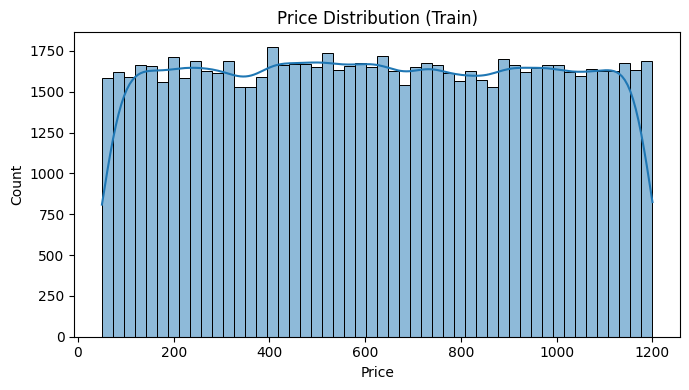

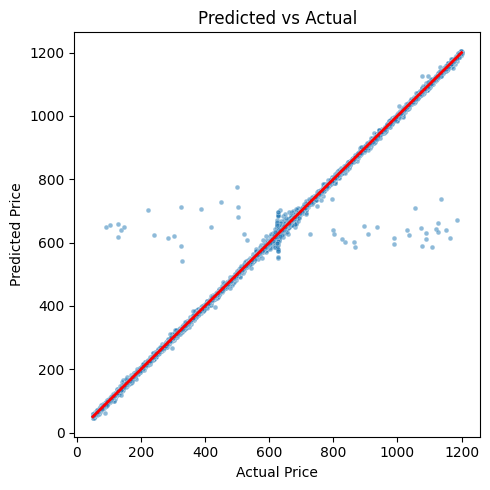

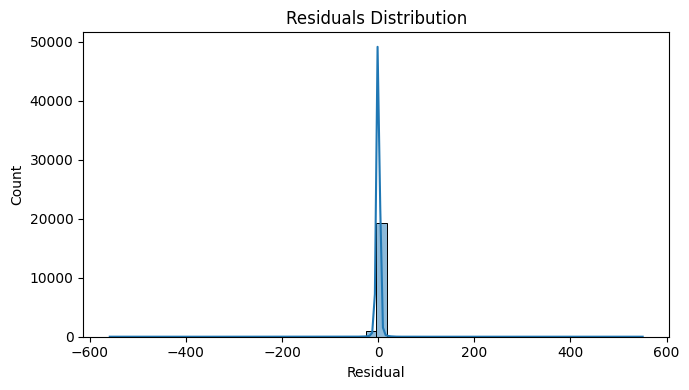

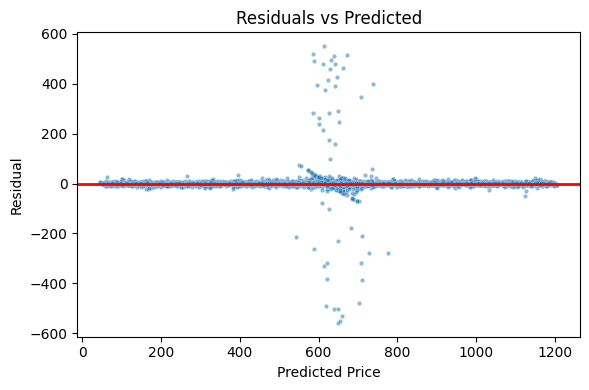

In [28]:
# Cell 8: Visualizations - Price distribution, Predicted vs Actual, Residuals

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Price distribution (Train set)
plt.figure(figsize=(7,4))
sns.histplot(y_train, bins=50, kde=True)
plt.title('Price Distribution (Train)')
plt.xlabel('Price')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

# Predicted vs Actual
plt.figure(figsize=(5,5))
sns.scatterplot(x=y_test, y=y_pred, s=12, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', lw=2)
plt.title('Predicted vs Actual')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.tight_layout()
plt.show()

# Residuals distribution
resid = y_test - y_pred
plt.figure(figsize=(7,4))
sns.histplot(resid, bins=50, kde=True)
plt.title('Residuals Distribution')
plt.xlabel('Residual')
plt.tight_layout()
plt.show()

# Residuals vs Predicted
plt.figure(figsize=(6,4))
sns.scatterplot(x=y_pred, y=resid, s=10, alpha=0.5)
plt.axhline(0, color='red', lw=2)
plt.title('Residuals vs Predicted')
plt.xlabel('Predicted Price')
plt.ylabel('Residual')
plt.tight_layout()
plt.show()


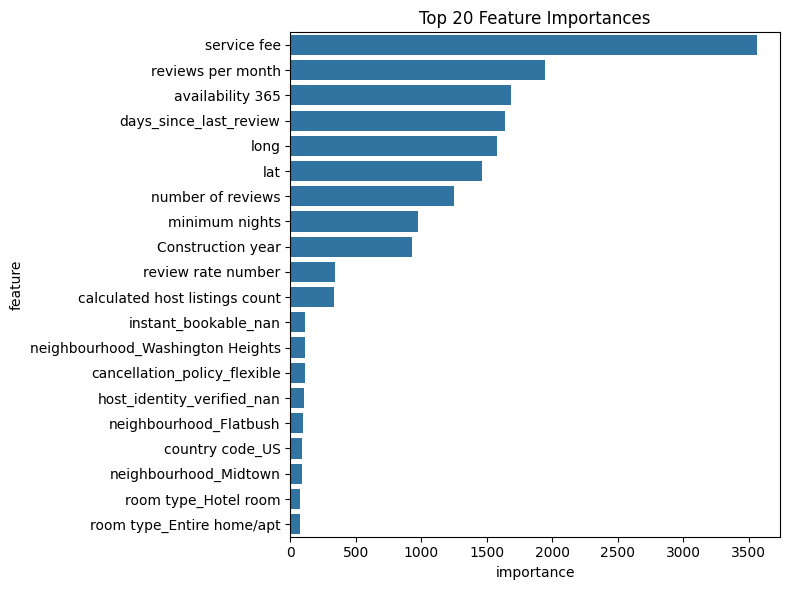

                             feature  importance
0                        service fee        3561
3                  reviews per month        1948
6                   availability 365        1687
10            days_since_last_review        1638
9                               long        1582
8                                lat        1461
2                  number of reviews        1249
1                     minimum nights         973
7                  Construction year         931
4                 review rate number         340
5     calculated host listings count         331
55              instant_bookable_nan         115
50  neighbourhood_Washington Heights         111
56      cancellation_policy_flexible         110
11        host_identity_verified_nan         103
32            neighbourhood_Flatbush          95
66                   country code_US          92
41             neighbourhood_Midtown          91
61              room type_Hotel room          78
60         room type

In [27]:
# Cell 9: Feature importances (LightGBM)

import pandas as pd

ohe = pipe.named_steps['preprocess'].named_transformers_['cat'].named_steps['onehot']
cat_names = list(ohe.get_feature_names_out(pipe.named_steps['preprocess'].transformers_[1][2]))
num_names = pipe.named_steps['preprocess'].transformers_[0][2]
feat_names = num_names + cat_names

importances = pipe.named_steps['model'].feature_importances_
fi = pd.DataFrame({'feature': feat_names, 'importance': importances}).sort_values('importance', ascending=False).head(20)

plt.figure(figsize=(8,6))
sns.barplot(data=fi, x='importance', y='feature', orient='h')
plt.title('Top 20 Feature Importances')
plt.tight_layout()
plt.show()

print(fi)


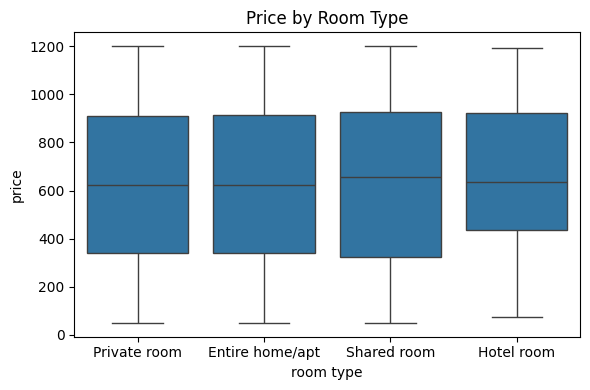

In [33]:
# Cell 10: Price vs key categorical and numeric features (EDA)

import seaborn as sns

if 'room type' in X_train.columns:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=X_train['room type'], y=y_train)
    plt.title('Price by Room Type')
    plt.tight_layout()
    plt.show()

for col in ['accommodates', 'bedrooms', 'bathrooms']:
    if col in X_train.columns:
        plt.figure(figsize=(6,4))
        sns.scatterplot(x=X_train[col], y=y_train, alpha=0.4, s=12)
        sns.regplot(x=X_train[col], y=y_train, scatter=False, color='red', lowess=True)
        plt.title('Price vs ' + col.capitalize())
        plt.tight_layout()
        plt.show()


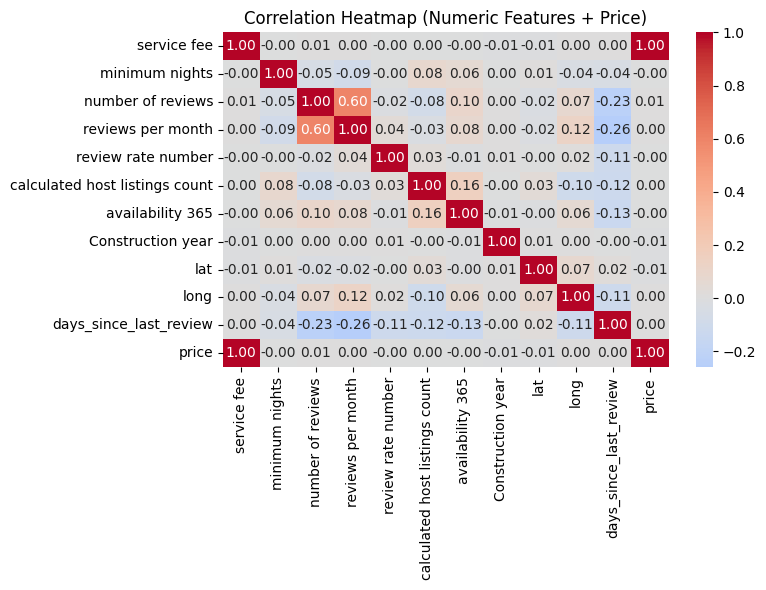

In [34]:
# Cell 12: Correlation heatmap (numeric only)

num_cols_plot = X_train.select_dtypes(include=['number']).copy()
num_cols_plot['price'] = y_train.values

corr = num_cols_plot.corr(numeric_only=True)

plt.figure(figsize=(8,6))
sns.heatmap(corr, cmap='coolwarm', center=0, square=False, annot=True, fmt=".2f")
plt.title('Correlation Heatmap (Numeric Features + Price)')
plt.tight_layout()
plt.show()
